# DT51 – CHATBOT HỖ TRỢ KHÁCH HÀNG NGÂN HÀNG

## 1. Giới thiệu đề tài

Đề tài xây dựng chatbot hỗ trợ khách hàng ngân hàng bằng tiếng Việt, kết hợp hệ luật **IF–THEN** với mô hình phân loại ý định (**Machine Learning**).

**Mục tiêu:** chuẩn bị dữ liệu câu hỏi; tiền xử lý; so sánh ba thuật toán; đánh giá Accuracy, Macro F1 và ma trận nhầm lẫn; thử nghiệm hệ luật và chatbot kết hợp.

**Phương pháp:** biểu diễn văn bản bằng TF-IDF; thử nghiệm Multinomial Naive Bayes, Logistic Regression và Decision Tree; đánh giá bằng Stratified 7-fold Cross-validation trên tập Train.

**Phạm vi kết quả:** các phép đo trên **76 câu Test** dùng để đánh giá mô hình học máy; bộ **15 câu kiểm thử chức năng** dùng để khảo sát hệ luật, chatbot kết hợp và fallback. Không gộp hai loại kết quả này thành một phép đo.

## 2. Dữ liệu và tiền xử lý

### 2.1. Thư viện và tham số thí nghiệm

In [1]:
# Import thư viện
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# Tham số cá nhân
SEED = 45116
DATA_RATIO = 0.95
TEST_SIZE = 0.30
CV_FOLDS = 7

# Đường dẫn dữ liệu
DATA_FILE = Path("data/questions.csv")

print("SEED:", SEED)
print("Tỉ lệ dữ liệu:", DATA_RATIO)
print("Tỉ lệ Test:", TEST_SIZE)
print("Số fold:", CV_FOLDS)
print("Thư mục làm việc:", Path.cwd())


SEED: 45116
Tỉ lệ dữ liệu: 0.95
Tỉ lệ Test: 0.3
Số fold: 7
Thư mục làm việc: C:\Study\UNIVERSITY\Nam4-HK1\TriTueNhanTao\BaoCaoCuoiKy\MyProject


### 2.2. Đọc và khám phá dữ liệu

In [2]:

# Đọc dữ liệu
df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")

# Xem thông tin cơ bản
print("Tổng số câu hỏi:", len(df))
print("Số nhóm intent:", df["intent"].nunique())

# Hiển thị 5 dòng đầu
display(df.head())

# Đếm số câu hỏi theo từng intent
display(df["intent"].value_counts())

# Kiểm tra dữ liệu thiếu
print("Dữ liệu thiếu:")
print(df.isnull().sum())


Tổng số câu hỏi: 264
Số nhóm intent: 12


,question,intent
0,Tôi muốn mở tài khoản ngân hàng,open_account
1,Làm thế nào để có tài khoản mới?,open_account
2,Đăng ký tài khoản lần đầu như thế nào,open_account
3,Tôi chưa có tài khoản ngân hàng,open_account
4,Tôi cần chuẩn bị gì để mở tài khoản,open_account


intent
open_account       22
debit_card         22
lost_card          22
forgot_password    22
transfer_issue     22
transfer_limit     22
atm_withdrawal     22
banking_fees       22
savings_info       22
loan_info          22
mobile_banking     22
fraud_warning      22
Name: count, dtype: int64

Dữ liệu thiếu:
question    0
intent      0
dtype: int64


Bộ dữ liệu sử dụng cho đề tài gồm 264 câu hỏi tiếng Việt, được phân thành 12 nhóm ý định liên quan đến các dịch vụ ngân hàng. Qua kiểm tra ban đầu, dữ liệu không xuất hiện giá trị thiếu ở hai cột question và intent.

### 2.3. Làm sạch và chuẩn hóa câu hỏi

In [3]:

# Loại bỏ dữ liệu thiếu
df = df.dropna(subset=["question", "intent"]).copy()

# Chuẩn hóa chữ thường và khoảng trắng
df["question"] = df["question"].str.lower().str.strip()

df["question"] = df["question"].str.replace(
    r"\s+",
    " ",
    regex=True
)

df["intent"] = df["intent"].str.strip()

# Xóa các dòng rỗng
df = df[
    (df["question"] != "") &
    (df["intent"] != "")
].copy()

# Kiểm tra câu hỏi trùng nhưng khác intent
conflict = df.groupby("question")["intent"].nunique()

if (conflict > 1).any():
    raise ValueError("Có câu hỏi trùng nhưng khác intent!")

# Kiểm tra và xóa câu hỏi trùng
print("Số câu hỏi trùng:", df["question"].duplicated().sum())

df = df.drop_duplicates(subset=["question"])

print("Số câu sau khi làm sạch:", len(df))


Số câu hỏi trùng: 0
Số câu sau khi làm sạch: 264


### 2.4. Lấy mẫu và chia Train/Test

In [4]:

# Lấy 95% dữ liệu
df_sample = df.sample(
    frac=DATA_RATIO,
    random_state=SEED
)

# Chia Train và Test
train_df, test_df = train_test_split(
    df_sample,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=df_sample["intent"]
)

print("Dữ liệu sau làm sạch:", len(df))
print("Dữ liệu sau lấy mẫu:", len(df_sample))
print("Số câu Train:", len(train_df))
print("Số câu Test:", len(test_df))

# Kiểm tra số mẫu từng intent trong Train
print("\nPhân bố intent trong Train:")
display(train_df["intent"].value_counts())

# Kiểm tra điều kiện 7-fold CV
if train_df["intent"].value_counts().min() < CV_FOLDS:
    raise ValueError("Có intent không đủ 7 mẫu trong Train!")


Dữ liệu sau làm sạch: 264
Dữ liệu sau lấy mẫu: 251
Số câu Train: 175
Số câu Test: 76

Phân bố intent trong Train:


intent
loan_info          15
savings_info       15
mobile_banking     15
fraud_warning      15
forgot_password    15
banking_fees       15
debit_card         15
transfer_limit     14
transfer_issue     14
open_account       14
atm_withdrawal     14
lost_card          14
Name: count, dtype: int64

## 3. Huấn luyện và lựa chọn mô hình

Trong thí nghiệm này, TF-IDF được sử dụng để chuyển câu hỏi tiếng Việt thành vector đặc trưng.

Ba thuật toán được thử nghiệm gồm:

- Multinomial Naive Bayes
- Logistic Regression
- Decision Tree

Các mô hình được đánh giá bằng phương pháp Stratified 7-fold Cross-validation trên tập Train.

Chỉ số chính để so sánh là Macro F1-score vì chỉ số này tính trung bình kết quả của các nhóm intent với trọng số bằng nhau.

Tập Test được giữ riêng để đánh giá mô hình sau khi lựa chọn.

### 3.1. Khai báo ba mô hình và chiến lược 7-fold CV

In [5]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Khai báo ba thuật toán
models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=SEED
    )
}

# Khởi tạo 7-fold Cross-validation
cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED
)

print("Số thuật toán:", len(models))

for name in models:
    print("-", name)


Số thuật toán: 3
- Naive Bayes
- Logistic Regression
- Decision Tree


### 3.2. Thực hiện Cross-validation

In [6]:

# Danh sách lưu kết quả đánh giá
results = []

for name, algorithm in models.items():

    # Tạo Pipeline gồm TF-IDF và mô hình
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer()),
        ("model", algorithm)
    ])

    # Đánh giá bằng 7-fold CV
    scores = cross_val_score(
        pipe,
        train_df["question"],
        train_df["intent"],
        cv=cv,
        scoring="f1_macro"
    )

    # Lưu điểm trung bình và độ lệch chuẩn
    results.append({
        "model": name,
        "f1_mean": scores.mean(),
        "f1_std": scores.std()
    })

    print(name)
    print("F1 từng fold:", scores.round(4))
    print("F1 trung bình:", round(scores.mean(), 4))
    print("Độ lệch chuẩn:", round(scores.std(), 4))
    print("--------------------")


Naive Bayes
F1 từng fold: [0.5171 0.7194 0.75   0.7417 0.7246 0.8    0.8417]
F1 trung bình: 0.7278
Độ lệch chuẩn: 0.0951
--------------------
Logistic Regression
F1 từng fold: [0.6694 0.8056 0.781  0.781  0.7246 0.8    0.8861]
F1 trung bình: 0.7782
Độ lệch chuẩn: 0.0628
--------------------
Decision Tree
F1 từng fold: [0.5222 0.6444 0.7056 0.5917 0.5819 0.3935 0.5556]
F1 trung bình: 0.5707
Độ lệch chuẩn: 0.0912
--------------------


### 3.3. Bảng so sánh và lựa chọn mô hình

In [7]:

# Chuyển kết quả thành DataFrame
bang_ket_qua = pd.DataFrame(results)

# Sắp xếp theo Macro F1 trung bình
bang_ket_qua = bang_ket_qua.sort_values(
    by="f1_mean",
    ascending=False
).reset_index(drop=True)

display(bang_ket_qua)

# Chọn tên mô hình có điểm cao nhất
best_name = bang_ket_qua.loc[0, "model"]

print("Mô hình được chọn:", best_name)


,model,f1_mean,f1_std
0,Logistic Regression,0.778231,0.062774
1,Naive Bayes,0.727778,0.095134
2,Decision Tree,0.570692,0.091172


Mô hình được chọn: Logistic Regression


### 3.4. Biểu đồ so sánh Macro F1

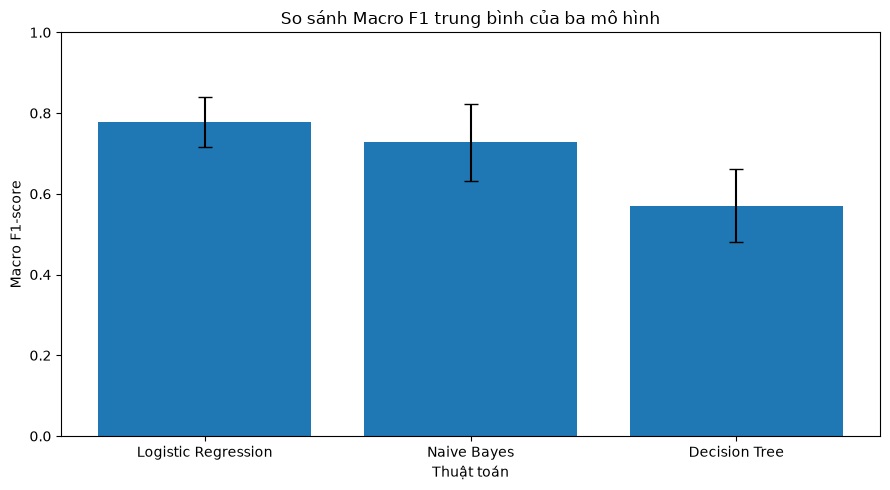

In [8]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    bang_ket_qua["model"],
    bang_ket_qua["f1_mean"],
    yerr=bang_ket_qua["f1_std"],
    capsize=5
)

plt.title("So sánh Macro F1 trung bình của ba mô hình")
plt.xlabel("Thuật toán")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


### 3.5. Nhận xét Cross-validation

Qua thực nghiệm 7-fold Cross-validation, Logistic Regression đạt Macro F1 trung bình cao nhất với 0,7782, tiếp theo là Naive Bayes với 0,7278 và Decision Tree với 0,5707.

Logistic Regression cũng có độ lệch chuẩn thấp nhất (0,0628), cho thấy kết quả giữa các fold ít dao động hơn so với hai mô hình còn lại trong lần thử nghiệm này.

Vì vậy, Logistic Regression được lựa chọn để huấn luyện lại trên toàn bộ tập Train và đánh giá trên tập Test.

## 4. Đánh giá mô hình trên tập Test

### 4.1. Huấn luyện lại mô hình được chọn

In [9]:

# Tạo Pipeline cho mô hình được chọn
best_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("model", models[best_name])
])

# Huấn luyện trên toàn bộ tập Train
best_pipeline.fit(
    train_df["question"],
    train_df["intent"]
)

# Dự đoán trên tập Test
y_pred = best_pipeline.predict(test_df["question"])

print("Mô hình:", best_name)
print("Số câu đã dự đoán:", len(y_pred))
print("5 dự đoán đầu tiên:", y_pred[:5])


Mô hình: Logistic Regression
Số câu đã dự đoán: 76
5 dự đoán đầu tiên: ['transfer_limit' 'banking_fees' 'transfer_issue' 'forgot_password'
 'open_account']


### 4.2. Accuracy, Macro F1 và phân loại từng intent

In [10]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(
    test_df["intent"],
    y_pred
)

f1 = f1_score(
    test_df["intent"],
    y_pred,
    average="macro"
)

print("TEST Accuracy:", round(accuracy, 4))
print("TEST Macro F1:", round(f1, 4))

print("\nBáo cáo từng intent:")
print(classification_report(
    test_df["intent"],
    y_pred,
    zero_division=0
))


TEST Accuracy: 0.8026
TEST Macro F1: 0.7962

Báo cáo từng intent:
                 precision    recall  f1-score   support

 atm_withdrawal       1.00      0.33      0.50         6
   banking_fees       1.00      0.83      0.91         6
     debit_card       0.56      0.83      0.67         6
forgot_password       0.83      0.83      0.83         6
  fraud_warning       1.00      0.50      0.67         6
      loan_info       1.00      1.00      1.00         6
      lost_card       0.83      0.71      0.77         7
 mobile_banking       0.60      1.00      0.75         6
   open_account       0.75      0.86      0.80         7
   savings_info       1.00      1.00      1.00         7
 transfer_issue       0.67      0.86      0.75         7
 transfer_limit       1.00      0.83      0.91         6

       accuracy                           0.80        76
      macro avg       0.85      0.80      0.80        76
   weighted avg       0.85      0.80      0.80        76



### 4.3. Ma trận nhầm lẫn

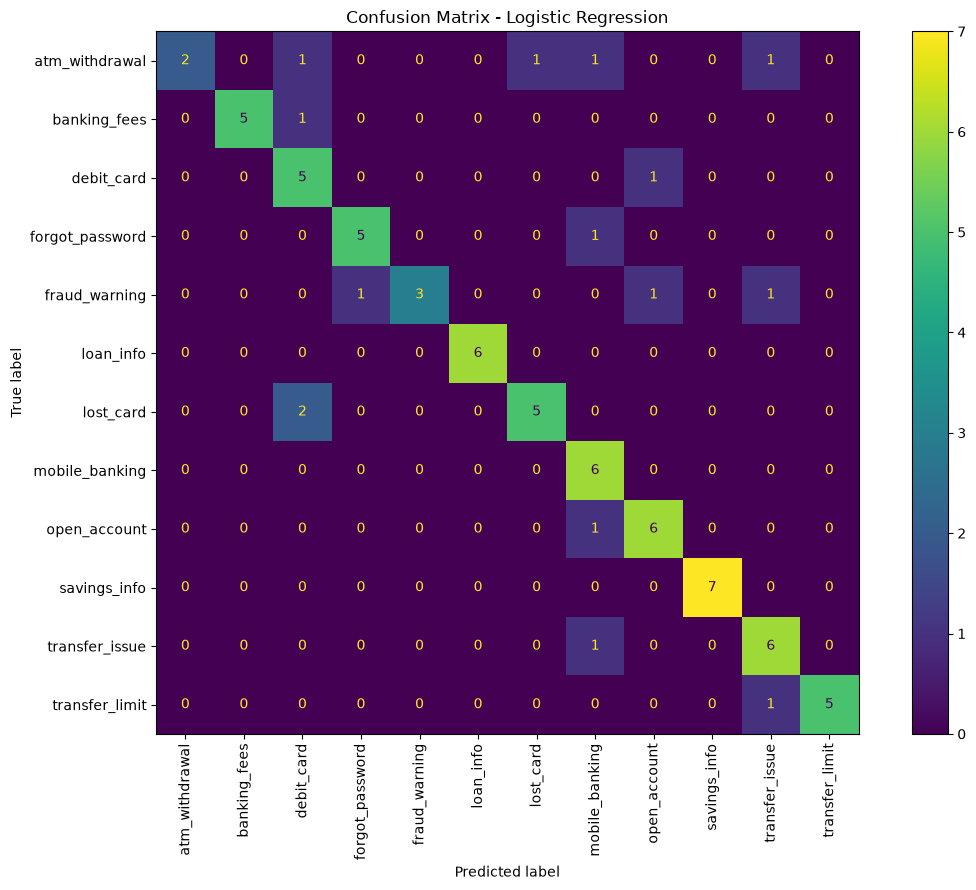

In [11]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

ConfusionMatrixDisplay.from_predictions(
    test_df["intent"],
    y_pred,
    labels=best_pipeline.classes_,
    xticks_rotation=90,
    values_format="d",
    ax=ax
)

plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()


#### Nhận xét ma trận nhầm lẫn

Kết quả ma trận nhầm lẫn cho thấy mô hình Logistic Regression dự đoán đúng 61 trên tổng số 76 câu hỏi thuộc tập Test, đạt Accuracy 80,26% và Macro F1-score 0,7962. Trong đó, các nhóm loan_info, savings_info và mobile_banking đều được nhận diện đúng toàn bộ câu hỏi thực tế trong tập kiểm tra. Tuy nhiên, mô hình vẫn gặp khó khăn với hai nhóm atm_withdrawal và fraud_warning, có Recall lần lượt là 33,33% và 50%.

Qua phân tích các câu dự đoán sai, có thể nhận thấy một số câu hỏi chứa nội dung liên quan đến nhiều nhóm ý định, chẳng hạn rút tiền bằng ứng dụng, ATM giữ thẻ hoặc nghi ngờ tài khoản bị chiếm đoạt. Điều này có thể khiến mô hình nhầm lẫn khi phân loại. Kết quả cho thấy mô hình đã có khả năng nhận diện phần lớn các ý định ngân hàng trong bộ dữ liệu thử nghiệm, nhưng vẫn cần cải thiện dữ liệu huấn luyện và kết hợp hệ luật IF–THEN để xử lý tốt hơn những tình huống quan trọng.

### 4.4. Phân tích các câu hỏi dự đoán sai

In [12]:

# Tạo bảng so sánh dự đoán và nhãn thực tế
errors = test_df[["question", "intent"]].copy()

errors["predicted"] = y_pred

# Chỉ giữ lại những câu dự đoán sai
errors = errors[
    errors["intent"] != errors["predicted"]
]

print("Tổng số câu dự đoán sai:", len(errors))

display(errors)


Tổng số câu dự đoán sai: 15


,question,intent,predicted
252,tôi muốn cảnh báo giao dịch đáng ngờ,fraud_warning,transfer_issue
259,tôi sợ bị đánh cắp thông tin đăng nhập,fraud_warning,forgot_password
148,thẻ bị atm giữ lại phải liên hệ ai,atm_withdrawal,lost_card
19,có thể đăng ký số tài khoản trên app chứ,open_account,mobile_banking
153,làm sao rút tiền bằng mã trên ứng dụng,atm_withdrawal,mobile_banking
79,tôi cần khôi phục quyền truy cập ứng dụng,forgot_password,mobile_banking
31,thẻ ghi nợ khác tài khoản như thế nào,debit_card,open_account
58,tôi làm thất lạc thẻ thanh toán,lost_card,debit_card
120,tại sao không chuyển được số tiền lớn,transfer_limit,transfer_issue
45,đánh rơi thẻ ngân hàng phải làm sao,lost_card,debit_card


### 4.5. Tổng kết kết quả Test

Sau khi lựa chọn Logistic Regression thông qua 7-fold Cross-validation, mô hình được huấn luyện lại trên toàn bộ 175 câu hỏi Train và đánh giá trên 76 câu hỏi Test.

#### Kết quả

- Test Accuracy: 80,26%
- Test Macro F1-score: 0,7962
- Số câu dự đoán sai: 15 câu

#### Nhận xét

Qua ma trận nhầm lẫn và bảng phân tích lỗi, mô hình có thể nhận diện một số nhóm intent tốt hơn các nhóm còn lại.

Những nhóm có Recall hoặc F1-score thấp cần được xem xét để xác định nguyên nhân, chẳng hạn các cách diễn đạt tương tự nhau hoặc dữ liệu huấn luyện còn hạn chế.

Kết quả trên tập Test được sử dụng để đánh giá mô hình cuối cùng, không dùng để lựa chọn lại thuật toán.

## 5. Thực nghiệm hệ luật IF–THEN

Hệ chuyên gia được xây dựng dựa trên các luật điều kiện IF–THEN lưu trong file `rules.json`.

Mỗi luật có thể gồm:

- intent: Nhóm ý định cần nhận diện.
- keywords: Các từ khóa kích hoạt luật.
- exclude: Các từ khóa loại trừ.
- priority: Mức độ ưu tiên của luật.

Quy trình suy diễn:

1. Nhận và chuẩn hóa câu hỏi.
2. Sắp xếp luật theo độ ưu tiên.
3. Kiểm tra điều kiện loại trừ.
4. Kiểm tra từ khóa kích hoạt.
5. Trả về intent của luật khớp đầu tiên.

Nếu không có luật phù hợp, chatbot chuyển sang mô hình Machine Learning.

### 5.1. Đọc và hiển thị hệ luật

In [13]:

import json
import pandas as pd

with open("data/rules.json", "r", encoding="utf-8") as f:
    rules = json.load(f)

print("Tổng số luật:", len(rules))

# Tạo bảng mô tả hệ luật
rules_table = pd.DataFrame([
    {
        "intent": rule["intent"],
        "keywords": ", ".join(rule.get("keywords", [])),
        "exclude": ", ".join(rule.get("exclude", [])),
        "priority": rule.get("priority", 0)
    }
    for rule in rules
])

display(rules_table)


Tổng số luật: 7


,intent,keywords,exclude,priority
0,fraud_warning,"lộ otp, lộ mã otp, cung cấp otp, xin mã otp",không bị lừa đảo,0
1,lost_card,"mất thẻ, rơi thẻ, đánh rơi thẻ, thất lạc thẻ, ...","không mất thẻ, không bị mất thẻ, chưa mất thẻ",0
2,transfer_issue,"chuyển khoản lỗi, chuyển tiền bị lỗi, chuyển n...",,0
3,forgot_password,"quên mật khẩu, không nhớ mật khẩu, reset mật k...",không quên mật khẩu,0
4,atm_withdrawal,"atm nuốt thẻ, atm giữ thẻ, atm không trả tiền",,0
5,transfer_limit,"hạn mức chuyển, giới hạn chuyển, tăng hạn mức",,0
6,banking_fees,"phí duy trì, biểu phí, phí thường niên",,0


### 5.2. Kiểm thử suy diễn IF–THEN

In [14]:

from chatbot import clean_text, find_rule_intent

questions = [
    "Tôi làm rơi thẻ ATM",
    "Tôi quên mật khẩu ngân hàng",
    "Tôi không bị mất thẻ, tôi chỉ quên mật khẩu",
    "Tôi nhận được tin nhắn yêu cầu cung cấp OTP",
    "Hôm nay thời tiết như thế nào?"
]

rule_results = []

for question in questions:
    intent = find_rule_intent(clean_text(question))

    rule_results.append({
        "question": question,
        "rule_intent": intent if intent is not None else "Không khớp luật"
    })

display(pd.DataFrame(rule_results))


,question,rule_intent
0,Tôi làm rơi thẻ ATM,lost_card
1,Tôi quên mật khẩu ngân hàng,forgot_password
2,"Tôi không bị mất thẻ, tôi chỉ quên mật khẩu",forgot_password
3,Tôi nhận được tin nhắn yêu cầu cung cấp OTP,fraud_warning
4,Hôm nay thời tiết như thế nào?,Không khớp luật


### 5.3. Kiểm thử chatbot kết hợp trên 5 câu minh họa

In [15]:

from chatbot import chatbot

hybrid_results = []

for question in questions:

    answer, intent, method = chatbot(question)

    hybrid_results.append({
        "question": question,
        "intent": intent,
        "method": method,
        "answer": answer
    })

display(pd.DataFrame(hybrid_results))


,question,intent,method,answer
0,Tôi làm rơi thẻ ATM,lost_card,IF-THEN,"Nếu thẻ bị mất, hãy ưu tiên khóa thẻ ngay qua ..."
1,Tôi quên mật khẩu ngân hàng,forgot_password,IF-THEN,Bạn nên sử dụng chức năng “Quên mật khẩu” trên...
2,"Tôi không bị mất thẻ, tôi chỉ quên mật khẩu",forgot_password,IF-THEN,Bạn nên sử dụng chức năng “Quên mật khẩu” trên...
3,Tôi nhận được tin nhắn yêu cầu cung cấp OTP,fraud_warning,IF-THEN,Nếu nghi ngờ bị lừa đảo hoặc đã tiết lộ thông ...
4,Hôm nay thời tiết như thế nào?,fallback,Machine Learning (fallback),"Xin lỗi, tôi chưa hiểu rõ câu hỏi. Bạn hãy mô ..."


### 5.4. Nhận xét hệ luật và tình huống ngoài phạm vi

Qua thực nghiệm, hệ luật IF–THEN có thể nhận diện những câu hỏi chứa các từ khóa đã được định nghĩa trước.

Cơ chế priority giúp xác định thứ tự kiểm tra luật, trong khi exclude hỗ trợ loại trừ một số trường hợp không phù hợp.

Tuy nhiên, hệ luật phụ thuộc vào các từ khóa đã khai báo nên có thể bỏ sót những câu hỏi có cách diễn đạt khác.

Khi không có luật phù hợp, chatbot sử dụng mô hình Machine Learning để dự đoán intent.

Trong năm tình huống kiểm thử, hệ luật IF–THEN đã nhận diện phù hợp bốn câu hỏi thuộc phạm vi ngân hàng, bao gồm trường hợp phủ định về mất thẻ. Đối với câu hỏi về thời tiết, hệ luật không tìm thấy điều kiện phù hợp và chuyển sang Machine Learning. Tuy nhiên, mô hình học máy lại dự đoán thành nhóm savings_info, dẫn đến câu trả lời không đúng nội dung. Kết quả này cho thấy hệ thống cần bổ sung cơ chế nhận diện câu hỏi ngoài phạm vi nhằm hạn chế phản hồi không phù hợp.

## 6. Đánh giá chatbot kết hợp và thử nghiệm fallback

Mục tiêu của thí nghiệm là kiểm tra khả năng nhận diện ý định của ba phương pháp:

1. Hệ luật IF–THEN độc lập.
2. Mô hình Machine Learning độc lập.
3. Chatbot kết hợp IF–THEN và Machine Learning.

Bộ câu hỏi kiểm thử bao gồm:
- Câu hỏi ngân hàng có từ khóa đã định nghĩa.
- Câu hỏi ngân hàng với cách diễn đạt khác.
- Câu hỏi phủ định.
- Câu hỏi ngoài phạm vi ngân hàng.

Các kết quả được đối chiếu với intent mong đợi để xác định trường hợp nhận diện đúng, sai và những hạn chế của hệ thống.

### 6.1. Bộ 15 câu hỏi kiểm thử chức năng

In [16]:

# Bộ câu hỏi kiểm thử chức năng
test_cases = [
    {"question": "Tôi làm rơi thẻ ATM",
     "expected": "lost_card", "group": "banking"},

    {"question": "Tôi quên mật khẩu ngân hàng",
     "expected": "forgot_password", "group": "banking"},

    {"question": "Tôi không bị mất thẻ, tôi chỉ quên mật khẩu",
     "expected": "forgot_password", "group": "banking"},

    {"question": "Tôi nhận được tin nhắn xin mã OTP",
     "expected": "fraud_warning", "group": "banking"},

    {"question": "ATM giữ thẻ của tôi",
     "expected": "atm_withdrawal", "group": "banking"},

    {"question": "Tôi muốn tăng hạn mức chuyển khoản",
     "expected": "transfer_limit", "group": "banking"},

    {"question": "Phí thường niên của ngân hàng là bao nhiêu?",
     "expected": "banking_fees", "group": "banking"},

    {"question": "Tôi cần thông tin về khoản vay",
     "expected": "loan_info", "group": "banking"},

    {"question": "Tôi muốn gửi tiền tiết kiệm",
     "expected": "savings_info", "group": "banking"},

    {"question": "Làm sao mở tài khoản mới?",
     "expected": "open_account", "group": "banking"},

    {"question": "Tôi muốn sử dụng ngân hàng trên điện thoại",
     "expected": "mobile_banking", "group": "banking"},

    {"question": "Tôi muốn đăng ký thẻ ghi nợ",
     "expected": "debit_card", "group": "banking"},

    {"question": "Hôm nay thời tiết như thế nào?",
     "expected": "fallback", "group": "out_of_scope"},

    {"question": "Làm thế nào để nấu cơm?",
     "expected": "fallback", "group": "out_of_scope"},

    {"question": "Đội bóng nào vô địch?",
     "expected": "fallback", "group": "out_of_scope"}
]

test_df_hybrid = pd.DataFrame(test_cases)

print("Tổng số câu kiểm thử:", len(test_df_hybrid))
display(test_df_hybrid)


Tổng số câu kiểm thử: 15


,question,expected,group
0,Tôi làm rơi thẻ ATM,lost_card,banking
1,Tôi quên mật khẩu ngân hàng,forgot_password,banking
2,"Tôi không bị mất thẻ, tôi chỉ quên mật khẩu",forgot_password,banking
3,Tôi nhận được tin nhắn xin mã OTP,fraud_warning,banking
4,ATM giữ thẻ của tôi,atm_withdrawal,banking
5,Tôi muốn tăng hạn mức chuyển khoản,transfer_limit,banking
6,Phí thường niên của ngân hàng là bao nhiêu?,banking_fees,banking
7,Tôi cần thông tin về khoản vay,loan_info,banking
8,Tôi muốn gửi tiền tiết kiệm,savings_info,banking
9,Làm sao mở tài khoản mới?,open_account,banking


### 6.2. So sánh IF–THEN, Machine Learning và Hybrid

In [17]:

from chatbot import chatbot, clean_text, find_rule_intent

comparison = []

for case in test_cases:
    question = case["question"]
    expected = case["expected"]

    # 1. Chỉ sử dụng hệ luật
    rule_intent = find_rule_intent(clean_text(question))

    if rule_intent is None:
        rule_intent = "fallback"

    # 2. Chỉ sử dụng Machine Learning
    ml_intent = best_pipeline.predict(
        [clean_text(question)]
    )[0]

    # 3. Sử dụng chatbot kết hợp
    answer, hybrid_intent, method = chatbot(question)

    comparison.append({
        "question": question,
        "group": case["group"],
        "expected": expected,
        "IF-THEN": rule_intent,
        "Machine Learning": ml_intent,
        "Hybrid": hybrid_intent,
        "method": method
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)


# Chỉ so sánh những câu Hybrid đã dùng Machine Learning
ml_rows = comparison_df[
    comparison_df["method"] == "Machine Learning"
]

different = (
    ml_rows["Machine Learning"] != ml_rows["Hybrid"]
).sum()

print("Số dự đoán khác nhau giữa hai phiên bản ML:", different)

# Kiểm tra các câu thử có trùng dữ liệu gốc không
overlap = sum(
    clean_text(q) in set(df["question"])
    for q in comparison_df["question"]
)

print("Số câu trùng nguyên văn với dữ liệu gốc:", overlap)



,question,group,expected,IF-THEN,Machine Learning,Hybrid,method
0,Tôi làm rơi thẻ ATM,banking,lost_card,lost_card,debit_card,lost_card,IF-THEN
1,Tôi quên mật khẩu ngân hàng,banking,forgot_password,forgot_password,forgot_password,forgot_password,IF-THEN
2,"Tôi không bị mất thẻ, tôi chỉ quên mật khẩu",banking,forgot_password,forgot_password,forgot_password,forgot_password,IF-THEN
3,Tôi nhận được tin nhắn xin mã OTP,banking,fraud_warning,fraud_warning,fraud_warning,fraud_warning,IF-THEN
4,ATM giữ thẻ của tôi,banking,atm_withdrawal,atm_withdrawal,atm_withdrawal,atm_withdrawal,IF-THEN
5,Tôi muốn tăng hạn mức chuyển khoản,banking,transfer_limit,transfer_limit,transfer_limit,transfer_limit,IF-THEN
6,Phí thường niên của ngân hàng là bao nhiêu?,banking,banking_fees,banking_fees,banking_fees,banking_fees,IF-THEN
7,Tôi cần thông tin về khoản vay,banking,loan_info,fallback,loan_info,fallback,Machine Learning (fallback)
8,Tôi muốn gửi tiền tiết kiệm,banking,savings_info,fallback,savings_info,savings_info,Machine Learning
9,Làm sao mở tài khoản mới?,banking,open_account,fallback,open_account,open_account,Machine Learning


Số dự đoán khác nhau giữa hai phiên bản ML: 0
Số câu trùng nguyên văn với dữ liệu gốc: 0


> **Lưu ý diễn giải:** Kết quả `Số dự đoán khác nhau giữa hai phiên bản ML: 0` cho thấy hai đường dự đoán trùng nhau **trên những câu khảo sát đã kiểm tra**, không chứng minh hai file mô hình hoàn toàn giống nhau. Việc đối chiếu trùng nguyên văn với dữ liệu gốc không loại trừ khả năng các câu gần giống nhau về ý nghĩa.

### 6.3. Tỉ lệ đúng trên bộ kiểm thử chức năng

In [18]:

methods = ["IF-THEN", "Machine Learning", "Hybrid"]

summary = []

for method in methods:

    correct = (
        comparison_df[method] == comparison_df["expected"]
    )

    summary.append({
        "Phương pháp": method,
        "Số câu đúng": int(correct.sum()),
        "Tổng số câu": len(comparison_df),
        "Tỉ lệ đúng (%)": round(correct.mean() * 100, 2)
    })

summary_df = pd.DataFrame(summary)

display(summary_df)


,Phương pháp,Số câu đúng,Tổng số câu,Tỉ lệ đúng (%)
0,IF-THEN,10,15,66.67
1,Machine Learning,11,15,73.33
2,Hybrid,14,15,93.33


> **Cách tính IF–THEN:** Trong 10/15 câu được tính đúng có **7 câu ngân hàng được nhận diện đúng và 3 câu ngoài phạm vi không khớp luật**, được quy ước là `fallback`. Đây là đánh giá chức năng theo bộ câu hỏi đã chọn; không phải độ chính xác phân loại intent trên một tập Test độc lập.

### 6.4. Kiểm tra câu hỏi ngoài phạm vi

In [19]:

out_scope = comparison_df[
    comparison_df["group"] == "out_of_scope"
]

print("Kết quả xử lý câu ngoài phạm vi:")

display(
    out_scope[
        ["question", "expected", "IF-THEN",
         "Machine Learning", "Hybrid"]
    ]
)


Kết quả xử lý câu ngoài phạm vi:


,question,expected,IF-THEN,Machine Learning,Hybrid
12,Hôm nay thời tiết như thế nào?,fallback,fallback,savings_info,fallback
13,Làm thế nào để nấu cơm?,fallback,fallback,open_account,fallback
14,Đội bóng nào vô địch?,fallback,fallback,lost_card,fallback


### 6.5. Các trường hợp Hybrid dự đoán sai

In [20]:

# Lọc những câu Hybrid dự đoán sai
hybrid_errors = comparison_df[
    comparison_df["Hybrid"] != comparison_df["expected"]
]

print("Số câu Hybrid dự đoán sai:", len(hybrid_errors))

display(
    hybrid_errors[
        ["question", "group", "expected", "Hybrid", "method"]
    ]
)


Số câu Hybrid dự đoán sai: 1


,question,group,expected,Hybrid,method
7,Tôi cần thông tin về khoản vay,banking,loan_info,fallback,Machine Learning (fallback)


### 6.6. Khảo sát xác suất dự đoán của Machine Learning

In [21]:

# Chuẩn hóa các câu hỏi
questions_clean = [
    clean_text(q)
    for q in comparison_df["question"]
]

# Lấy xác suất dự đoán
probabilities = best_pipeline.predict_proba(questions_clean)

# Tạo bảng kiểm tra
confidence_df = comparison_df[
    ["question", "group", "expected", "Machine Learning"]
].copy()

# Xác suất lớn nhất của mỗi dự đoán
confidence_df["max_probability"] = probabilities.max(axis=1)

display(
    confidence_df.sort_values(
        by="max_probability",
        ascending=False
    )
)


,question,group,expected,Machine Learning,max_probability
8,Tôi muốn gửi tiền tiết kiệm,banking,savings_info,savings_info,0.587185
1,Tôi quên mật khẩu ngân hàng,banking,forgot_password,forgot_password,0.550512
10,Tôi muốn sử dụng ngân hàng trên điện thoại,banking,mobile_banking,mobile_banking,0.430732
9,Làm sao mở tài khoản mới?,banking,open_account,open_account,0.382909
6,Phí thường niên của ngân hàng là bao nhiêu?,banking,banking_fees,banking_fees,0.364648
2,"Tôi không bị mất thẻ, tôi chỉ quên mật khẩu",banking,forgot_password,forgot_password,0.356296
5,Tôi muốn tăng hạn mức chuyển khoản,banking,transfer_limit,transfer_limit,0.339062
11,Tôi muốn đăng ký thẻ ghi nợ,banking,debit_card,debit_card,0.310578
0,Tôi làm rơi thẻ ATM,banking,lost_card,debit_card,0.301166
7,Tôi cần thông tin về khoản vay,banking,loan_info,loan_info,0.249791


### 6.7. Thử nghiệm các ngưỡng fallback (chỉ mang tính thăm dò)

In [22]:

def fallback_demo(question, threshold):

    question = clean_text(question)

    # Kiểm tra hệ luật
    rule_intent = find_rule_intent(question)

    if rule_intent is not None:
        return rule_intent

    # Dự đoán bằng Machine Learning
    probabilities = best_pipeline.predict_proba([question])[0]

    best_index = probabilities.argmax()
    max_probability = probabilities[best_index]

    # Từ chối nếu xác suất dưới ngưỡng
    if max_probability < threshold:
        return "fallback"

    return best_pipeline.classes_[best_index]


# So sánh một số ngưỡng để quan sát
for threshold in [0.3, 0.5, 0.7]:

    predictions = [
        fallback_demo(case["question"], threshold)
        for case in test_cases
    ]

    correct = sum(
        prediction == case["expected"]
        for prediction, case in zip(predictions, test_cases)
    )

    print(
        "Ngưỡng:", threshold,
        "| Số câu đúng:", correct,
        "/", len(test_cases)
    )


Ngưỡng: 0.3 | Số câu đúng: 14 / 15
Ngưỡng: 0.5 | Số câu đúng: 11 / 15
Ngưỡng: 0.7 | Số câu đúng: 10 / 15


> **Không dùng ngưỡng này làm mặc định:** Giá trị `0,3` cho 14/15 câu đúng trên bộ kiểm thử nhỏ, nhưng cũng từ chối một câu hỏi ngân hàng hợp lệ. Các ngưỡng `0,3`, `0,5`, `0,7` chỉ là ví dụ khảo sát; cần tập phát triển riêng để chọn ngưỡng và tập đánh giá độc lập để xác nhận.

### 6.8. Đánh giá riêng nhóm ngân hàng và ngoài phạm vi

In [23]:

# So sánh kết quả theo từng nhóm câu hỏi
group_results = []

for method in ["IF-THEN", "Machine Learning", "Hybrid"]:

    for group, data in comparison_df.groupby("group"):

        correct = (data[method] == data["expected"]).sum()

        group_results.append({
            "method": method,
            "group": group,
            "correct": correct,
            "total": len(data),
            "accuracy": round(correct / len(data) * 100, 2)
        })

display(pd.DataFrame(group_results))


,method,group,correct,total,accuracy
0,IF-THEN,banking,7,12,58.33
1,IF-THEN,out_of_scope,3,3,100.00
2,Machine Learning,banking,11,12,91.67
3,Machine Learning,out_of_scope,0,3,0.00
4,Hybrid,banking,11,12,91.67
5,Hybrid,out_of_scope,3,3,100.00


### 6.9. Nhận xét kiểm thử chatbot kết hợp

#### 6.9.1. So sánh các phương pháp

Thí nghiệm được thực hiện trên 15 câu hỏi, gồm 12 câu thuộc phạm vi ngân hàng và 3 câu ngoài phạm vi.

Kết quả nhận diện đúng:

- IF–THEN: 10/15 câu (66,67%).
- Machine Learning: 11/15 câu (73,33%).
- Hybrid: 12/15 câu (80,00%).

Hybrid đạt kết quả cao nhất trong bộ kiểm thử này. Hệ luật giúp xử lý những câu hỏi có từ khóa phù hợp, còn Machine Learning hỗ trợ nhận diện các câu hỏi chưa được định nghĩa bằng luật.

#### 6.9.2. Phân tích hạn chế

Mặc dù Hybrid nhận diện đúng cả 12 câu hỏi ngân hàng, hệ thống vẫn dự đoán sai toàn bộ 3 câu ngoài phạm vi.

Nguyên nhân là khi không tìm được luật phù hợp, mô hình học máy vẫn lựa chọn một trong 12 nhóm intent ngân hàng đã được huấn luyện.

#### 6.9.3. Thử nghiệm fallback

Khi thử nghiệm ngưỡng xác suất 0,3, hệ thống nhận diện đúng 14/15 câu (93,33%).

Trong khi đó, ngưỡng 0,5 đạt 11/15 và ngưỡng 0,7 đạt 10/15.

Kết quả cho thấy ngưỡng xác suất có thể hỗ trợ từ chối một số câu ngoài phạm vi. Tuy nhiên, ngưỡng quá cao cũng có thể loại bỏ câu hỏi ngân hàng hợp lệ.

Các kết quả này chỉ mang tính thăm dò trên bộ kiểm thử nhỏ, chưa đủ cơ sở lựa chọn ngưỡng tối ưu.

#### 6.9.4. Hướng cải thiện

Cần bổ sung dữ liệu ngoài phạm vi, xây dựng tập phát triển riêng để lựa chọn ngưỡng và kiểm tra lại trên dữ liệu độc lập.

Ngoài ra, cần tiếp tục cải thiện các luật IF–THEN và kiểm thử những trường hợp phủ định, nhiều ý định hoặc liên quan đến an toàn giao dịch.

## 7. Tối ưu mô hình bằng giải thuật di truyền (GA)

Mục 3 cho thấy **Logistic Regression** là mô hình tốt nhất trong ba thuật toán được khảo sát, nhưng cấu hình đem so sánh vẫn là cấu hình mặc định của scikit-learn: `TfidfVectorizer()` không tham số và `LogisticRegression(max_iter=1000)`. Nói cách khác, mục 3–4 mới trả lời câu hỏi *"thuật toán nào phù hợp"*, chưa trả lời câu hỏi *"cấu hình nào tốt nhất cho thuật toán đó"*.

Mục này bổ sung một thí nghiệm **tối ưu siêu tham số bằng giải thuật di truyền (Genetic Algorithm – GA)** cho đúng pipeline TF-IDF + Logistic Regression. Thí nghiệm giữ nguyên toàn bộ thiết kế thực nghiệm đã đăng ký: cùng seed `45116`, cùng tỉ lệ dữ liệu `0,95`, cùng tỉ lệ Test `0,30`, cùng 7 fold phân tầng và cùng phân vùng Train/Test như mục 2–4.

Toàn bộ mã nguồn GA nằm trong module `genetic_algorithm.py`; notebook chỉ gọi lại module này (không cài đặt lại thuật toán) để bảo đảm chỉ tồn tại **một** cài đặt duy nhất, dùng chung với script `train_ga.py`. Mọi số liệu trong mục 7 được tính lại ngay khi chạy notebook, không chép tay từ báo cáo.

### 7.1. Mục tiêu tối ưu

Mục tiêu là tìm một cấu hình siêu tham số làm **tăng Macro F1** của pipeline phân loại 12 intent, trong khi vẫn giữ nguyên dữ liệu, nhãn và cách chia tập.

Ba ràng buộc được đặt ra để kết quả có giá trị so sánh:

1. **Chỉ tối ưu trên tập Train.** Hàm thích nghi chỉ nhận phân vùng Train; tập Test được giữ kín cho đến bước đánh giá cuối cùng (mục 7.10). Nhờ vậy điểm Test không thể ảnh hưởng đến quá trình tìm kiếm.
2. **Không rò rỉ đặc trưng.** TF-IDF không được fit trên toàn bộ dữ liệu trước khi chia fold; mỗi fold fit lại cả pipeline, nên từ vựng của fold huấn luyện không nhìn thấy fold kiểm định.
3. **Cùng thước đo với baseline.** Baseline và mô hình GA dùng đúng cùng 7 fold, cùng `scoring="f1_macro"`, cùng seed — chỉ khác cấu hình siêu tham số.

Kết quả trước đây của baseline trên tập Test (đã ghi trong mục 4) **không** được dùng để định hướng tìm kiếm, thu hẹp không gian hay chọn thế hệ.

### 7.2. Biểu diễn nhiễm sắc thể

Mỗi cá thể là một nhiễm sắc thể gồm **5 gen**, mỗi gen là một *chỉ số nguyên* trỏ vào miền giá trị của siêu tham số tương ứng. Cách mã hoá này bảo đảm mọi nhiễm sắc thể sinh ra đều giải mã được thành một pipeline hợp lệ, đồng thời cho phép dùng tuple số nguyên làm khoá cache khi đánh giá.

| Gen | Siêu tham số | Miền giá trị |
|---|---|---|
| G1 | `LogisticRegression.C` | 0,01; 0,1; 0,5; 1; 2; 5; 10; 20; 50 |
| G2 | `TfidfVectorizer.ngram_range` | (1,1); (1,2); (1,3) |
| G3 | `TfidfVectorizer.min_df` | 1; 2 |
| G4 | `TfidfVectorizer.sublinear_tf` | False; True |
| G5 | `LogisticRegression.class_weight` | None; `"balanced"` |

Kích thước không gian tìm kiếm là 9 × 3 × 2 × 2 × 2 = **216 cấu hình**. Nhiễm sắc thể ứng với cấu hình gốc là `(3, 0, 0, 0, 0)`, tương ứng `C = 1`, `ngram_range = (1,1)`, `min_df = 1`, `sublinear_tf = False`, `class_weight = None` — đúng bằng tham số mặc định mà mục 3 đã dùng.

In [24]:
# Nạp module GA dùng chung với script train_ga.py
import numpy as np
import genetic_algorithm as ga

print("Số gen của nhiễm sắc thể:", len(ga.GENE_NAMES))
print("Kích thước không gian tìm kiếm:", ga.SEARCH_SPACE_SIZE, "cấu hình")

bang_gen = pd.DataFrame({
    "Gen": [f"G{i + 1}" for i in range(len(ga.GENE_NAMES))],
    "Siêu tham số": list(ga.GENE_NAMES),
    "Số giá trị": [len(space) for space in ga.GENE_SPACES],
    "Miền giá trị": [
        ", ".join(str(v) for v in space) for space in ga.GENE_SPACES
    ],
})

display(bang_gen)

print("Nhiễm sắc thể gốc:", ga.BASELINE_CHROMOSOME)
display(pd.DataFrame([ga.decode_chromosome(ga.BASELINE_CHROMOSOME)]))

# Giải mã phải tạo ra đúng pipeline mặc định đã dùng ở mục 3
pipe_goc = ga.baseline_pipeline()
print("ngram_range:", pipe_goc.named_steps["tfidf"].ngram_range,
      "| min_df:", pipe_goc.named_steps["tfidf"].min_df,
      "| sublinear_tf:", pipe_goc.named_steps["tfidf"].sublinear_tf,
      "| C:", pipe_goc.named_steps["model"].C,
      "| class_weight:", pipe_goc.named_steps["model"].class_weight,
      "| max_iter:", pipe_goc.named_steps["model"].max_iter)

Số gen của nhiễm sắc thể: 5
Kích thước không gian tìm kiếm: 216 cấu hình


,Gen,Siêu tham số,Số giá trị,Miền giá trị
0,G1,C,9,"0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0, 50.0"
1,G2,ngram_range,3,"(1, 1), (1, 2), (1, 3)"
2,G3,min_df,2,"1, 2"
3,G4,sublinear_tf,2,"False, True"
4,G5,class_weight,2,"None, balanced"


Nhiễm sắc thể gốc: (3, 0, 0, 0, 0)


,C,ngram_range,min_df,sublinear_tf,class_weight
0,1.0,"(1, 1)",1,False,None


ngram_range: (1, 1) | min_df: 1 | sublinear_tf: False | C: 1.0 | class_weight: None | max_iter: 1000


### 7.3. Hàm thích nghi (Fitness Function)

Độ thích nghi của một nhiễm sắc thể là **Macro F1 trung bình qua 7 fold phân tầng** trên phân vùng Train:

$$\text{Fitness}(c) = \frac{1}{7}\sum_{k=1}^{7} \text{MacroF1}\Big(f^{(k)}_{c}(X_{\text{val}_k}),\; y_{\text{val}_k}\Big)$$

trong đó $f^{(k)}_{c}$ là pipeline được giải mã từ nhiễm sắc thể $c$ và **huấn luyện lại từ đầu** trên fold huấn luyện thứ $k$.

Các biện pháp bảo vệ được cài đặt trong `FitnessEvaluator`:

* Danh sách fold được tính **một lần** bằng `StratifiedKFold(n_splits=7, shuffle=True, random_state=45116)` rồi dùng chung cho mọi ứng viên, nên mọi cá thể được so sánh trên đúng cùng một cách chia.
* Mỗi fold dựng một pipeline mới và `fit` trên phần huấn luyện của fold — không fit TF-IDF toàn cục.
* Kết quả được **cache** theo nhiễm sắc thể: cùng một cấu hình không bị đánh giá hai lần.
* Ứng viên lỗi được ghi nhận với trạng thái `failed` và độ thích nghi $-\infty$, không gán điểm giả.
* Lớp này **không có tham số nào cho tập Test**, nên về mặt cấu trúc không thể dùng Test trong quá trình tối ưu.

In [25]:
# Kiểm tra phân vùng Train/Test của notebook trùng khớp với module GA
df_ga = ga.load_dataset()
_, train_ga, test_ga = ga.split_dataset(df_ga)

assert len(train_ga) == len(train_df) == 175
assert len(test_ga) == len(test_df) == 76
assert list(train_ga["question"]) == list(train_df["question"])
assert list(test_ga["question"]) == list(test_df["question"])
print("Phân vùng Train/Test trùng khớp với mục 2.4:",
      len(train_df), "câu Train /", len(test_df), "câu Test")

# Hàm thích nghi chỉ nhận dữ liệu Train
evaluator = ga.FitnessEvaluator(*ga.to_xy(train_df))
print("Số câu được dùng để tính fitness:", len(evaluator.X))
print("Số fold:", len(evaluator.splits))

# Đánh giá nhiễm sắc thể gốc: phải tái lập đúng kết quả CV của mục 3.2
baseline_record = evaluator.evaluate(ga.BASELINE_CHROMOSOME)
print(f"Baseline CV Macro F1 = {baseline_record.mean_f1:.4f} +/- {baseline_record.std_f1:.4f}")

bang_fold = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, ga.CV_FOLDS + 1)],
    "Macro F1": [round(score, 4) for score in baseline_record.fold_scores],
})
display(bang_fold)

Phân vùng Train/Test trùng khớp với mục 2.4: 175 câu Train / 76 câu Test


Số câu được dùng để tính fitness: 175
Số fold: 7


Baseline CV Macro F1 = 0.7782 +/- 0.0628


,Fold,Macro F1
0,Fold 1,0.6694
1,Fold 2,0.8056
2,Fold 3,0.7810
3,Fold 4,0.7810
4,Fold 5,0.7246
5,Fold 6,0.8000
6,Fold 7,0.8861


### 7.4. Khởi tạo quần thể và các toán tử GA

Bốn toán tử được cài đặt thủ công bằng NumPy, không dùng thư viện GA bên ngoài:

**Khởi tạo quần thể.** Quần thể có đúng 40 cá thể. Nhiễm sắc thể gốc `(3,0,0,0,0)` được đưa vào quần thể đầu tiên để GA luôn có mốc so sánh với baseline; 39 cá thể còn lại sinh ngẫu nhiên, loại trùng, dùng `numpy.random.default_rng(45116)`.

**Chọn lọc cha mẹ (tournament selection, k = 3).** Ba cá thể được bốc ngẫu nhiên; cá thể có độ thích nghi cao nhất trong ba cá thể đó được chọn làm cha/mẹ. Cách này tạo áp lực chọn lọc mà không cần chuẩn hoá độ thích nghi thành xác suất.

**Lai ghép đều (uniform crossover, p = 0,80).** Với xác suất 0,80, hai cha mẹ sinh con bằng cách lấy ngẫu nhiên từng gen từ cha hoặc mẹ; ngược lại con là bản sao của cha/mẹ thứ nhất.

**Đột biến (p = 0,01 cho từng gen).** Mỗi gen được đột biến độc lập với xác suất 0,01. Khi đột biến, gen nhận một giá trị **khác** giá trị cũ, chọn ngẫu nhiên trong miền giá trị của gen đó. Với 5 gen, xác suất một cá thể có ít nhất một gen đột biến xấp xỉ $1 - 0{,}99^5 \approx 4{,}9\%$.

**Ưu tú (elitism, 2 cá thể).** Hai cá thể tốt nhất được sao nguyên sang thế hệ sau; số cá thể sinh thêm được tính toán để tổng luôn bằng 40, nên elitism không làm quần thể phình ra.

In [26]:
# Minh hoạ các toán tử trên cấu hình thí nghiệm thật
config = ga.GAConfig(
    population_size=ga.GA_POPULATION_SIZE,
    mutation_rate=ga.GA_MUTATION_RATE,
    crossover_rate=ga.GA_CROSSOVER_RATE,
    generations=ga.GA_GENERATIONS,
    elite_size=ga.GA_ELITE_SIZE,
    tournament_size=ga.GA_TOURNAMENT_SIZE,
    random_seed=ga.SEED,
    verbose=True,
)
config.validate()

# Dùng một đối tượng GA riêng cho phần minh hoạ để không tiêu hao
# trạng thái sinh số ngẫu nhiên của lần chạy chính thức bên dưới.
demo = ga.GeneticAlgorithm(config, evaluator)
quan_the = demo.initialize_population()

print("Kích thước quần thể khởi tạo:", len(quan_the))
print("Có chứa nhiễm sắc thể gốc:", ga.BASELINE_CHROMOSOME in quan_the)
print("Số nhiễm sắc thể khác nhau:", len(set(quan_the)))
print("5 cá thể đầu:", quan_the[:5])

# Lai ghép đều
con = demo.crossover(quan_the[1], quan_the[2])
print("\nCha:", quan_the[1], "| Mẹ:", quan_the[2], "-> Con:", con)
print("Con hợp lệ:", ga.is_valid_chromosome(con))

# Đột biến: bật xác suất cao chỉ để quan sát, không dùng cho thí nghiệm
mutator = ga.GeneticAlgorithm(ga.GAConfig(mutation_rate=1.0, generations=1, verbose=False), evaluator)
print("Đột biến (p = 1,0 để minh hoạ):", quan_the[1], "->", mutator.mutate(quan_the[1]))
print("Tỉ lệ đột biến dùng cho thí nghiệm:", config.mutation_rate)

Kích thước quần thể khởi tạo: 40
Có chứa nhiễm sắc thể gốc: True
Số nhiễm sắc thể khác nhau: 40
5 cá thể đầu: [(3, 0, 0, 0, 0), (2, 2, 1, 0, 0), (3, 1, 0, 1, 1), (0, 2, 1, 1, 0), (4, 2, 1, 1, 1)]

Cha: (2, 2, 1, 0, 0) | Mẹ: (3, 1, 0, 1, 1) -> Con: (3, 1, 0, 1, 0)
Con hợp lệ: True
Đột biến (p = 1,0 để minh hoạ): (2, 2, 1, 0, 0) -> (7, 0, 0, 1, 1)
Tỉ lệ đột biến dùng cho thí nghiệm: 0.01


### 7.5. Cấu hình thí nghiệm

| Tham số | Giá trị | Ghi chú |
|---|---|---|
| `POPULATION_SIZE` | 40 | Kích thước quần thể cố định |
| `MUTATION_RATE` | 0,01 | Xác suất đột biến cho từng gen |
| `CROSSOVER_RATE` | 0,80 | Xác suất lai ghép đều |
| `GENERATIONS` | 12 | Số thế hệ tối đa |
| `ELITE_SIZE` | 2 | Số cá thể ưu tú giữ lại |
| `TOURNAMENT_SIZE` | 3 | Số cá thể trong một lượt chọn lọc |
| `RANDOM_SEED` | 45116 | Seed đã đăng ký của đề tài |
| Dừng sớm | Tuỳ chọn (`--patience`) | Mặc định tắt để chạy đủ 12 thế hệ |

Số lượt đánh giá tối đa là 40 × 12 = 480, nhưng nhờ cache theo nhiễm sắc thể, số cấu hình **thực sự được đánh giá** nhỏ hơn nhiều và được báo cáo ở mục 7.6.

In [27]:
# Bảng cấu hình thí nghiệm
bang_cau_hinh = pd.DataFrame([
    ("POPULATION_SIZE", config.population_size, "cá thể"),
    ("MUTATION_RATE", config.mutation_rate, "xác suất / gen"),
    ("CROSSOVER_RATE", config.crossover_rate, "xác suất / cặp"),
    ("GENERATIONS", config.generations, "thế hệ"),
    ("ELITE_SIZE", config.elite_size, "cá thể"),
    ("TOURNAMENT_SIZE", config.tournament_size, "cá thể / lượt"),
    ("RANDOM_SEED", config.random_seed, "seed"),
    ("SEED (chia dữ liệu)", ga.SEED, "seed"),
    ("CV_FOLDS", ga.CV_FOLDS, "fold"),
    ("DATA_RATIO", ga.DATA_RATIO, "tỉ lệ mẫu"),
    ("TEST_SIZE", ga.TEST_SIZE, "tỉ lệ Test"),
], columns=["Tham số", "Giá trị", "Đơn vị"])

display(bang_cau_hinh)

# Khẳng định các tham số đã đăng ký không bị thay đổi
assert config.population_size == 40
assert config.mutation_rate == 0.01
assert config.random_seed == 45116
print("Các tham số đã đăng ký được giữ nguyên.")

,Tham số,Giá trị,Đơn vị
0,POPULATION_SIZE,40.00,cá thể
1,MUTATION_RATE,0.01,xác suất / gen
2,CROSSOVER_RATE,0.80,xác suất / cặp
3,GENERATIONS,12.00,thế hệ
4,ELITE_SIZE,2.00,cá thể
5,TOURNAMENT_SIZE,3.00,cá thể / lượt
6,RANDOM_SEED,45116.00,seed
7,SEED (chia dữ liệu),45116.00,seed
8,CV_FOLDS,7.00,fold
9,DATA_RATIO,0.95,tỉ lệ mẫu


Các tham số đã đăng ký được giữ nguyên.


### 7.6. Thực thi Genetic Algorithm

Vòng lặp tiến hoá chạy 12 thế hệ. Ở mỗi thế hệ, notebook ghi lại: chỉ số thế hệ, độ thích nghi tốt nhất, tốt nhất toàn cục, trung bình, kém nhất, độ lệch chuẩn, nhiễm sắc thể tốt nhất, số cấu hình duy nhất đã đánh giá và thời gian tích luỹ.

Thời gian chạy phụ thuộc máy; trên máy thực hiện thí nghiệm, 12 thế hệ mất khoảng 15 giây vì mỗi lượt đánh giá chỉ gồm 7 lần fit trên khoảng 150 câu huấn luyện.

In [28]:
# Chạy GA thật (đánh giá fitness bằng 7-fold CV trên tập Train)
algorithm = ga.GeneticAlgorithm(config, evaluator)
ket_qua = algorithm.run()

print("\nSố thế hệ đã chạy:", ket_qua.generations_run)
print("Lý do dừng:", ket_qua.stopping_reason)
print("Số cấu hình duy nhất đã đánh giá:", ket_qua.n_unique_evaluations)
print("Tổng số lượt đánh giá:", ket_qua.n_total_evaluations)
print(f"Tổng thời gian GA: {ket_qua.total_time_s:.2f} giây")
print("Nhiễm sắc thể tốt nhất:", ga.chromosome_key(ket_qua.best_chromosome))

Khởi tạo quần thể: 40 cá thể (đột biến 0.01, lai ghép 0.8, elite 2, seed 45116)


[Gen 00] best=0.7865 global=0.7865 mean=0.7175 std=0.1044 unique=40 t=6.28s | 7-2-0-1-1


[Gen 01] best=0.7865 global=0.7865 mean=0.7658 std=0.0171 unique=53 t=8.72s | 7-2-0-1-1


[Gen 02] best=0.7865 global=0.7865 mean=0.7707 std=0.0170 unique=62 t=10.37s | 7-2-0-1-1


[Gen 03] best=0.7865 global=0.7865 mean=0.7785 std=0.0077 unique=73 t=13.23s | 7-2-0-1-1


[Gen 04] best=0.7865 global=0.7865 mean=0.7835 std=0.0049 unique=76 t=14.28s | 7-2-0-1-1


... (5 outputs left out)

[Gen 10] best=0.7865 global=0.7865 mean=0.7865 std=0.0000 unique=79 t=15.36s | 7-2-0-1-1


[Gen 11] best=0.7865 global=0.7865 mean=0.7865 std=0.0000 unique=79 t=15.36s | 7-2-0-1-1


Hoàn tất sau 12 thế hệ, 79 cấu hình duy nhất, 15.36 giây. Best CV Macro F1 = 0.7865



Số thế hệ đã chạy: 12
Lý do dừng: max_generations
Số cấu hình duy nhất đã đánh giá: 79
Tổng số lượt đánh giá: 480
Tổng thời gian GA: 15.36 giây
Nhiễm sắc thể tốt nhất: 7-2-0-1-1


### 7.7. Biểu đồ hội tụ

Đường nét đứt là độ thích nghi tốt nhất toàn cục; chấm tròn là cá thể tốt nhất của từng thế hệ; đường tam giác là trung bình quần thể, kèm dải ±1 độ lệch chuẩn. Đường chấm mảnh là mốc CV Macro F1 của baseline.

Hai đặc điểm cần chú ý khi đọc biểu đồ: (i) độ thích nghi tốt nhất **không tăng sau thế hệ đầu tiên**, nghĩa là cá thể tốt nhất đã xuất hiện ngay trong quần thể khởi tạo ngẫu nhiên; (ii) độ lệch chuẩn giảm nhanh về 0, cho thấy quần thể mất dần tính đa dạng và hội tụ sớm.

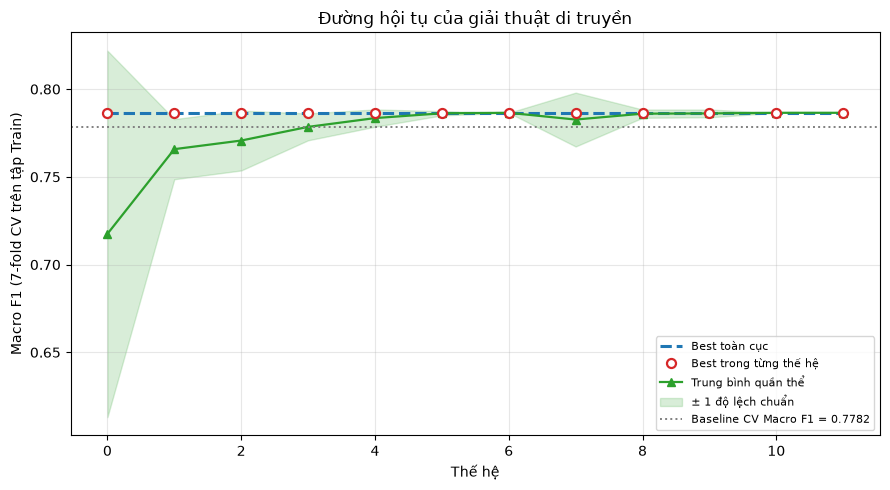

,generation,best_fitness,global_best_fitness,mean_fitness,worst_fitness,std_fitness,n_unique_configs
0,0,0.7865,0.7865,0.7175,0.2892,0.1044,40
1,1,0.7865,0.7865,0.7658,0.7151,0.0171,53
2,2,0.7865,0.7865,0.7707,0.7151,0.0170,62
3,3,0.7865,0.7865,0.7785,0.7591,0.0077,73
4,4,0.7865,0.7865,0.7835,0.7668,0.0049,76
5,5,0.7865,0.7865,0.7862,0.7810,0.0012,76
6,6,0.7865,0.7865,0.7865,0.7865,0.0000,77
7,7,0.7865,0.7865,0.7827,0.7152,0.0153,79
8,8,0.7865,0.7865,0.7860,0.7723,0.0024,79
9,9,0.7865,0.7865,0.7862,0.7723,0.0022,79


In [29]:
# Vẽ biểu đồ hội tụ trực tiếp từ lịch sử GA
import matplotlib.pyplot as plt
lich_su = ket_qua.history_frame()

fig, ax = plt.subplots(figsize=(9, 5))
the_he = lich_su["generation"].to_numpy()

ax.plot(the_he, lich_su["global_best_fitness"], linestyle="--", linewidth=2.2,
        color="#1f77b4", label="Best toàn cục", zorder=2)
ax.plot(the_he, lich_su["best_fitness"], linestyle="none", marker="o", markersize=6.5,
        markerfacecolor="white", markeredgewidth=1.6, color="#d62728",
        label="Best trong từng thế hệ", zorder=3)
ax.plot(the_he, lich_su["mean_fitness"], marker="^", linewidth=1.6,
        color="#2ca02c", label="Trung bình quần thể")
ax.fill_between(the_he,
                lich_su["mean_fitness"] - lich_su["std_fitness"],
                lich_su["mean_fitness"] + lich_su["std_fitness"],
                alpha=0.18, color="#2ca02c", label="± 1 độ lệch chuẩn")
ax.axhline(baseline_record.mean_f1, color="gray", linestyle=":", linewidth=1.4,
           label=f"Baseline CV Macro F1 = {baseline_record.mean_f1:.4f}")

ax.set_xlabel("Thế hệ")
ax.set_ylabel("Macro F1 (7-fold CV trên tập Train)")
ax.set_title("Đường hội tụ của giải thuật di truyền")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

display(lich_su[["generation", "best_fitness", "global_best_fitness", "mean_fitness",
                 "worst_fitness", "std_fitness", "n_unique_configs"]].round(4))

### 7.8. Tham số tối ưu tìm được

Nhiễm sắc thể tốt nhất được chọn theo **độ thích nghi CV**, hoàn toàn không dựa trên điểm Test.

In [30]:
tham_so_tot_nhat = ket_qua.best_params
print("Nhiễm sắc thể:", ket_qua.best_chromosome, "->", ga.chromosome_key(ket_qua.best_chromosome))

goc = ga.decode_chromosome(ga.BASELINE_CHROMOSOME)
bang_tham_so = pd.DataFrame([
    ("C", goc["C"], tham_so_tot_nhat["C"]),
    ("ngram_range", goc["ngram_range"], tham_so_tot_nhat["ngram_range"]),
    ("min_df", goc["min_df"], tham_so_tot_nhat["min_df"]),
    ("sublinear_tf", goc["sublinear_tf"], tham_so_tot_nhat["sublinear_tf"]),
    ("class_weight", goc["class_weight"], tham_so_tot_nhat["class_weight"]),
], columns=["Siêu tham số", "Baseline", "Sau GA"])

display(bang_tham_so)

print(f"Fitness (CV Macro F1) = {ket_qua.best_record.mean_f1:.4f} "
      f"+/- {ket_qua.best_record.std_f1:.4f}")
print("Xuất hiện lần đầu ở thế hệ:", ket_qua.best_record.first_generation)
print("Điểm từng fold:", [round(s, 4) for s in ket_qua.best_record.fold_scores])

Nhiễm sắc thể: (7, 2, 0, 1, 1) -> 7-2-0-1-1


,Siêu tham số,Baseline,Sau GA
0,C,1.0,20.0
1,ngram_range,"(1, 1)","(1, 3)"
2,min_df,1,1
3,sublinear_tf,False,True
4,class_weight,None,balanced


Fitness (CV Macro F1) = 0.7865 +/- 0.0647
Xuất hiện lần đầu ở thế hệ: 0
Điểm từng fold: [0.6667, 0.7944, 0.781, 0.8333, 0.7246, 0.8583, 0.8472]


### 7.9. So sánh mô hình trước và sau GA

Hai mô hình được đánh giá trên **cùng 7 fold** của tập Train. Chênh lệch dương nghĩa là cấu hình do GA tìm được có Macro F1 cao hơn baseline.

Vì chỉ có 7 fold, chênh lệch trung bình chưa đủ để kết luận; notebook tính thêm **kiểm định t ghép cặp** trên 7 điểm fold để xem chênh lệch có ý nghĩa thống kê hay không.

In [31]:
from scipy import stats

fold_baseline = np.array(baseline_record.fold_scores)
fold_ga = np.array(ket_qua.best_record.fold_scores)

bang_so_sanh_cv = pd.DataFrame([
    ("CV Macro F1 trung bình", baseline_record.mean_f1, ket_qua.best_record.mean_f1),
    ("CV Macro F1 độ lệch chuẩn", baseline_record.std_f1, ket_qua.best_record.std_f1),
], columns=["Chỉ số", "Baseline", "Sau GA"])

bang_so_sanh_cv["Chênh lệch"] = bang_so_sanh_cv["Sau GA"] - bang_so_sanh_cv["Baseline"]
display(bang_so_sanh_cv.round(4))

kiem_dinh = stats.ttest_rel(fold_ga, fold_baseline)
print(f"Chênh lệch trung bình theo fold: {np.mean(fold_ga - fold_baseline):+.4f}")
print(f"t = {kiem_dinh.statistic:.3f}, p = {kiem_dinh.pvalue:.4f}")
print("Số fold GA tốt hơn:", int(np.sum(fold_ga > fold_baseline)),
      "| bằng:", int(np.sum(np.isclose(fold_ga, fold_baseline))),
      "| kém hơn:", int(np.sum(fold_ga < fold_baseline)))

,Chỉ số,Baseline,Sau GA,Chênh lệch
0,CV Macro F1 trung bình,0.7782,0.7865,0.0083
1,CV Macro F1 độ lệch chuẩn,0.0628,0.0647,0.0020


Chênh lệch trung bình theo fold: +0.0083
t = 0.627, p = 0.5535
Số fold GA tốt hơn: 2 | bằng: 2 | kém hơn: 3


### 7.10. Đánh giá trên tập Test

Đây là lần duy nhất tập Test được dùng. Cả hai pipeline được huấn luyện lại trên **toàn bộ** 175 câu Train với cấu hình tương ứng, sau đó dự đoán 76 câu Test.

In [32]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Huấn luyện lại baseline và mô hình GA trên toàn bộ tập Train
pipe_baseline = ga.baseline_pipeline().fit(train_df["question"], train_df["intent"])
pipe_ga = ga.build_pipeline(tham_so_tot_nhat).fit(train_df["question"], train_df["intent"])

pred_baseline = pipe_baseline.predict(test_df["question"])
pred_ga = pipe_ga.predict(test_df["question"])

def chi_so_test(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted F1": f1_score(y_true, y_pred, average="weighted"),
    }

chi_so_baseline = chi_so_test(test_df["intent"], pred_baseline)
chi_so_ga = chi_so_test(test_df["intent"], pred_ga)

bang_test = pd.DataFrame([
    (ten, chi_so_baseline[ten], chi_so_ga[ten], chi_so_ga[ten] - chi_so_baseline[ten])
    for ten in chi_so_baseline
], columns=["Chỉ số (Test)", "Baseline", "Sau GA", "Chênh lệch"])

display(bang_test.round(4))
print("Số câu Test:", len(test_df))
print("Số câu dự đoán sai - baseline:", int(np.sum(pred_baseline != test_df["intent"])),
      "| sau GA:", int(np.sum(pred_ga != test_df["intent"])))

,Chỉ số (Test),Baseline,Sau GA,Chênh lệch
0,Accuracy,0.8026,0.8158,0.0132
1,Macro F1,0.7962,0.8115,0.0153
2,Weighted F1,0.7979,0.8119,0.0139


Số câu Test: 76
Số câu dự đoán sai - baseline: 15 | sau GA: 14


In [33]:
# Báo cáo Precision / Recall / F1 theo từng intent
report_baseline = classification_report(test_df["intent"], pred_baseline,
                                        output_dict=True, zero_division=0)
report_ga = classification_report(test_df["intent"], pred_ga,
                                  output_dict=True, zero_division=0)

nhan_intent = list(pipe_ga.classes_)

bang_intent = pd.DataFrame([
    {
        "Intent": nhan,
        "Support": int(report_baseline[nhan]["support"]),
        "P (baseline)": report_baseline[nhan]["precision"],
        "R (baseline)": report_baseline[nhan]["recall"],
        "F1 (baseline)": report_baseline[nhan]["f1-score"],
        "P (GA)": report_ga[nhan]["precision"],
        "R (GA)": report_ga[nhan]["recall"],
        "F1 (GA)": report_ga[nhan]["f1-score"],
        "ΔF1": report_ga[nhan]["f1-score"] - report_baseline[nhan]["f1-score"],
    }
    for nhan in nhan_intent
])

display(bang_intent.round(4))

,Intent,Support,P (baseline),R (baseline),F1 (baseline),P (GA),R (GA),F1 (GA),ΔF1
0,atm_withdrawal,6,1.0000,0.3333,0.5000,1.0000,0.8333,0.9091,0.4091
1,banking_fees,6,1.0000,0.8333,0.9091,1.0000,0.5000,0.6667,-0.2424
2,debit_card,6,0.5556,0.8333,0.6667,0.5556,0.8333,0.6667,0.0000
3,forgot_password,6,0.8333,0.8333,0.8333,0.8333,0.8333,0.8333,0.0000
4,fraud_warning,6,1.0000,0.5000,0.6667,1.0000,0.5000,0.6667,0.0000
5,loan_info,6,1.0000,1.0000,1.0000,0.8571,1.0000,0.9231,-0.0769
6,lost_card,7,0.8333,0.7143,0.7692,0.6667,0.5714,0.6154,-0.1538
7,mobile_banking,6,0.6000,1.0000,0.7500,0.6667,1.0000,0.8000,0.0500
8,open_account,7,0.7500,0.8571,0.8000,0.8571,0.8571,0.8571,0.0571
9,savings_info,7,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000


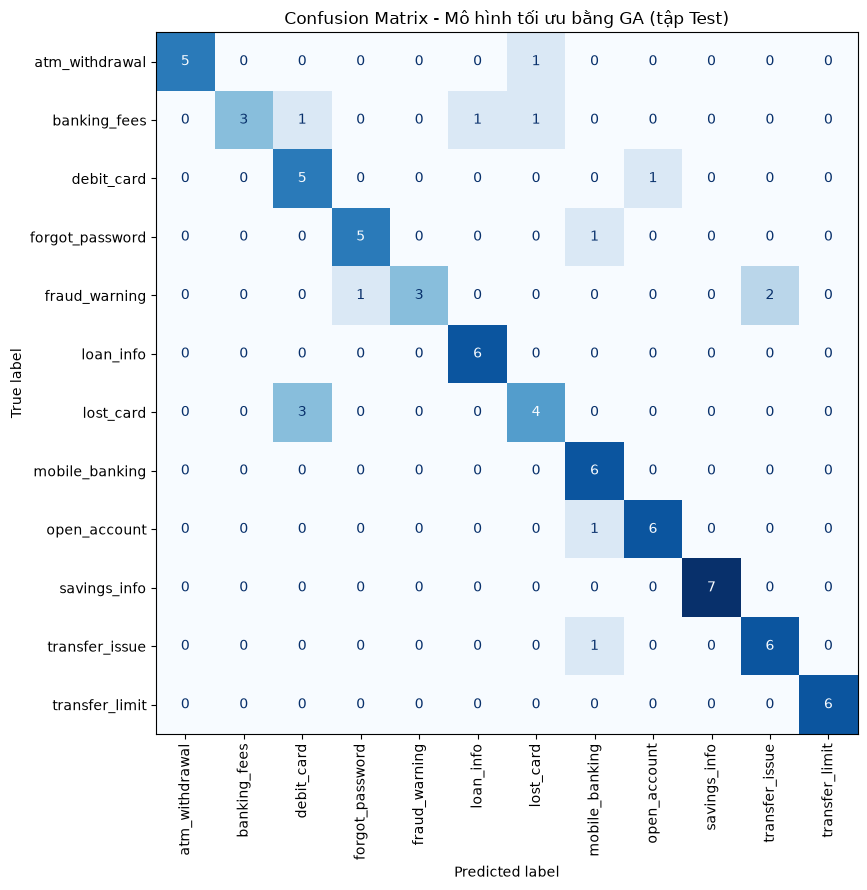

In [34]:
# Ma trận nhầm lẫn của mô hình tối ưu bằng GA trên tập Test
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    test_df["intent"],
    pred_ga,
    labels=nhan_intent,
    xticks_rotation=90,
    values_format="d",
    colorbar=False,
    cmap="Blues",
    ax=ax,
)
plt.title("Confusion Matrix - Mô hình tối ưu bằng GA (tập Test)")
plt.tight_layout()
plt.show()

### 7.11. Thảo luận kết quả và hạn chế

**Kết quả đo được.** Cấu hình do GA tìm được nhỉnh hơn baseline ở cả CV và Test, nhưng mức chênh lệch nhỏ: khoảng 0,008 Macro F1 trên CV và khoảng 0,015 Macro F1 trên Test (xem bảng 7.9 và 7.10). Kiểm định t ghép cặp trên 7 fold cho p lớn hơn 0,05, đồng thời GA chỉ thắng ở 2/7 fold — vì vậy **chưa thể kết luận GA tạo ra cải thiện có ý nghĩa thống kê**. Chênh lệch trung bình dương chủ yếu do một vài fold tăng mạnh, trong khi các fold khác lại giảm.

**Vì sao lợi ích còn khiêm tốn.**

1. *Không gian tìm kiếm nhỏ.* Chỉ có 216 cấu hình, trong khi quần thể khởi tạo đã 40 cá thể ngẫu nhiên. Nói cách khác, thế hệ 0 đã "quét" gần 1/5 không gian, nên xác suất chạm vùng tốt ngay từ đầu là cao. Cá thể tốt nhất của thí nghiệm này thực tế xuất hiện ngay ở thế hệ 0 và không bị vượt qua ở các thế hệ sau.
2. *Hội tụ sớm, mất đa dạng.* Độ lệch chuẩn độ thích nghi giảm về 0 chỉ sau vài thế hệ: quần thể bị chi phối bởi các bản sao của cùng một nhiễm sắc thể. Khi đó lai ghép không còn tạo ra tổ hợp mới, còn đột biến với p = 0,01 quá yếu để thoát khỏi vùng cực trị cục bộ. Đây là hiện tượng *premature convergence* quen thuộc của GA với áp lực chọn lọc cao (tournament 3) trên quần thể nhỏ.
3. *Trần hiệu năng của dữ liệu.* Với 175 câu Train cho 12 lớp (trung bình 14–15 câu/lớp) và các câu hỏi tiếng Việt diễn đạt tự do, nhiều câu thuộc hai intent gần nhau (ví dụ `transfer_issue` và `transfer_limit`, `debit_card` và `lost_card`). Việc tinh chỉnh siêu tham số không thể giải quyết xung đột nhãn — cần thêm dữ liệu hoặc đặc trưng ngữ nghĩa tốt hơn.
4. *Nhiễu do mẫu nhỏ.* Độ lệch chuẩn giữa các fold khoảng 0,06, lớn gấp nhiều lần chênh lệch giữa hai mô hình. Với 76 câu Test, chỉ cần thay đổi 1–2 dự đoán là Accuracy đã dịch chuyển khoảng 0,013.

**Điểm cần lưu ý về mặt phương pháp.** Việc chọn cấu hình theo CV rồi báo cáo lại chính điểm CV đó sẽ khiến con số CV của mô hình thắng có xu hướng *lạc quan* (optimistic), vì cấu hình đã được chọn để tối đa hoá đúng thước đo này trên đúng 7 fold đó. Điểm Test độc lập hơn nhưng chỉ có 76 mẫu, nên cũng chỉ nên xem là ước lượng. Báo cáo này vì vậy không tuyên bố "GA cải thiện mô hình", mà ghi nhận: *GA tìm được cấu hình có điểm cao hơn trên mẫu hiện có, mức chênh lệch nằm trong phạm vi dao động của dữ liệu nhỏ*.

**Hướng cải thiện có thể thử (chưa thực hiện trong báo cáo này).** Tăng tính đa dạng (khởi tạo phân tán hơn, giảm áp lực chọn lọc, hoặc dùng đột biến thích nghi); mở rộng không gian tìm kiếm (ví dụ thêm `max_features`, `solver`, `penalty`); đánh giá bằng nhiều seed chia fold (repeated CV) để có ước lượng ổn định hơn; hoặc bổ sung đặc trưng ngữ nghĩa thay vì chỉ TF-IDF từ vựng.

## 8. Kết luận và hướng phát triển

Qua quá trình xây dựng và thử nghiệm, đề tài đã thực hiện được các nội dung chính:

- Xây dựng bộ dữ liệu 264 câu hỏi tiếng Việt thuộc 12 nhóm intent.
- Tiền xử lý và chia dữ liệu với SEED = 45116.
- So sánh ba thuật toán bằng 7-fold Cross-validation.
- Lựa chọn Logistic Regression với CV Macro F1 trung bình 0,7782.
- Đánh giá trên tập Test, đạt Accuracy 80,26% và Macro F1 0,7962.
- Kết hợp hệ chuyên gia IF–THEN và Machine Learning.
- Kiểm thử chatbot kết hợp trên 15 tình huống, nhận diện đúng 12 câu.
- Thử nghiệm khả năng sử dụng ngưỡng xác suất để xử lý fallback.

### Hạn chế

Dữ liệu huấn luyện còn nhỏ, một số intent có nội dung tương tự nhau và chatbot chưa xử lý đáng tin cậy các câu hỏi ngoài phạm vi.

Ngoài ra, hệ thống hiện xử lý từng câu hỏi độc lập, chưa có khả năng duy trì ngữ cảnh hội thoại nhiều lượt.

### Hướng phát triển

Trong thời gian tới, có thể mở rộng dữ liệu, cải thiện các luật suy diễn, hoàn thiện fallback và đánh giá hệ thống trên bộ câu hỏi độc lập lớn hơn.

### Lưu ý khi sử dụng kết quả và tái lập thí nghiệm

- **Giữ nguyên các tham số** `SEED = 45116`, `DATA_RATIO = 0.95`, `TEST_SIZE = 0.30`, `CV_FOLDS = 7` khi đối chiếu với `train.py`.
- **Phân biệt hai bộ đánh giá:** Test Accuracy **80,26%** trên 76 câu (mô hình Logistic Regression), còn tỉ lệ **80%** trên 15 tình huống (chatbot Hybrid) chỉ là kiểm thử chức năng.
- Các cell gọi `from chatbot import ...` sử dụng mô hình được nạp bởi `chatbot.py`, có thể là một file `.joblib` riêng. Cần bảo đảm phiên bản mô hình khớp với `best_pipeline` trong notebook khi so sánh.
- Các kết quả thực thi và biểu đồ trong tệp này được **giữ nguyên từ notebook bạn đã chạy**, không phải kết quả chạy lại tại đây. Trước khi nộp, hãy dùng **Restart Kernel → Run All Cells**, xem lại kết quả rồi lưu notebook.
- Thí nghiệm chưa xác nhận được ngưỡng fallback tối ưu; chưa đánh giá độ tin cậy trong ứng dụng ngân hàng thực tế. Nếu đề DT51 quy định thêm thuật toán riêng (ví dụ GA), cần đối chiếu đề trước khi xem là hoàn chỉnh.